# State of the art: lifetime PD by survival, competing risks and macro satellites

**Question:** Do the three lifetime-PD models of the product match the survival methods the research recommends, where do they under-predict a crisis vintage, and what does treating prepayment as censoring instead of a competing exit cost in default probability and in ECL?

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 to 05 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- place the three lifetime-PD rungs of C06 (Kaplan-Meier, a discrete-time hazard with macro covariates, a Cox model) in the survival methods the research found, and say which methods the product does not run;
- show why the discrete-time logit and the Cox model give nearly the same coefficients when the period hazard is small;
- check the signs of the macro coefficients against economic expectation, as a validator must, and read what a wrong sign does to a scenario ECL;
- compare the three rungs on the same data by discrimination, integrated Brier score and calibration of the cumulative PD, pooled and for the crisis vintage;
- measure what treating prepayment as censoring costs against a competing-risks view, and read the macro satellite's factor paths with their reversion to the long run.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
RUNGS = ("L0-km", "L1-dth", "L2-cox")
RUNG_NAME = {"L0-km": "Kaplan-Meier", "L1-dth": "discrete-time logit", "L2-cox": "Cox"}
MACRO = {
    "unemployment_rate": "unemployment rate",
    "real_gdp_growth": "real GDP growth",
    "prime_rate": "prime rate",
}
LIGHT = {"green": "green", "amber": "amber", "red": "red"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C06 at the reporting date 2008-12-31: the SBA 7(a) small-business loans (U.S. Government Works, licence class `mirror-allowed`) and the Federal Reserve 2026 scenario shapes (mirror-allowed). Two committed files are read.

- `data/derived/C06/models-rd-2008-12.json`: the fit of the three rungs (`fit.ladder`: the coefficients and standard errors, the baseline of the Kaplan-Meier and Cox rungs), the macro scaler of the hazard rung (`model[].details.macro_scaler`), the one-factor conversion (`fit.pit`: the history of the systematic factor and the satellite) and the scenario definitions with their factor paths (`fit.scenario_definitions`).
- `data/derived/C06/rd-2008-12.json`: `outputs.rung_comparison` (discrimination, integrated Brier score and 12-month calibration gap of each rung), and the `tests` rows of the lifetime back-test by origination cohort and rung, whose `extras` keep the gap of each horizon.

The three rungs were fitted by the pipeline (`data-pipeline/pipeline/cases/c06/ladder.py`, with `statsmodels`) on the loans known at the reporting date; the raw loan file is not committed, so this notebook **reads the fits and the tests, and does not refit**. Everything recomputed below is arithmetic on committed numbers or an engine call on them.

In [2]:
# Load the model file and the reporting-date artifact and list the three rungs
from riskvalidation.provisions import ecl as ecl_engine, term_structure as tsm
from riskvalidation.validation import ifrs9

ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C06"
models = json.loads((DERIVED / "models-rd-2008-12.json").read_text(encoding="utf-8"))
case = json.loads((DERIVED / "rd-2008-12.json").read_text(encoding="utf-8"))
fit = models["fit"]
ladder = {r["rung_id"]: r for r in fit["ladder"]}
print("engine that baked the artifact:", case["provenance"]["riskvalidation_version"])
print("engine installed now:", md.version("riskvalidation"))
for slot in models["model"]:
    loans, defaults = slot["parameters"]["n_loans"]["value"], slot["parameters"]["n_defaults"]["value"]
    print(f"{RUNG_NAME[slot['id']]:22s} | loans {int(loans)} | defaults {int(defaults)}")

engine that baked the artifact: 1.0.1
engine installed now: 1.0.1
Kaplan-Meier           | loans 871618 | defaults 74139
discrete-time logit    | loans 871618 | defaults 74139
Cox                    | loans 871618 | defaults 74139


## Method

All three rungs model the time from the reporting date to default, with prepayment as censoring, and give the cumulative PD $F(t)$ that notebook 01 turns into an ECL. They differ in how they let the hazard depend on the loan and on the macroeconomy.

**L0, Kaplan-Meier.** One pooled curve by loan age. The product-limit estimator of the survival is $\hat S(t) = \prod_{t_i \le t}\bigl(1 - d_i/n_i\bigr)$, with $d_i$ the defaults and $n_i$ the loans at risk at age $t_i$. It has no covariates and no macroeconomy, so its ranking is only the age ranking.

**L1, discrete-time hazard with macro covariates.** A logistic regression on loan-period records (Shumway, 2001; Botha and Verster, 2025):

$$\mathrm{logit}\,h_i(t) = \alpha(a_{it}) + \boldsymbol\beta^\top \mathbf{x}_i + \boldsymbol\gamma^\top \mathbf{m}_{t-\ell}$$

with $\alpha$ a step function of loan age (age bands), $\mathbf{x}_i$ the loan covariates (size, term, sector, revolving) and $\mathbf{m}_{t-\ell}$ the macro variables lagged $\ell = 1$ quarter, standardised. It is the rung that carries the scenarios.

**L2, Cox proportional hazards** (Cox, 1972): $h_i(t) = h_0(t)\exp(\boldsymbol\beta^\top \mathbf{x}_i)$, with loan age as the time scale and Breslow ties. The `statsmodels` implementation the pipeline uses has no time-varying covariates, so this rung has **no macroeconomy** and cannot carry a scenario.

For a small period hazard $h$, $\mathrm{logit}\,h = \log\bigl(h/(1-h)\bigr) \approx \log h$, so the coefficients of L1 and L2 on the common covariates should agree. The macroeconomy enters the term structure of L1 only.

**The validation of a rung** is the lifetime back-test of notebook 05 and the rung comparison: Harrell's concordance (the probability that of two loans the one with the shorter survival has the higher predicted risk, ties as one half), the integrated Brier score of the survival prediction and the 12-month calibration gap between the predicted and the observed cumulative PD. The one-factor view (BCBS 2005; Gordy 2003) links the macroeconomy to the PD through a systematic factor $z$ that a satellite regresses on macro variables; the weights on short-term forecasts decay to long-term values (ECB letter of 1 April 2020).

## State of the art

The research (dossiers 02 and 04) found the following methods for the term structure of default under IFRS 9. The last column says what the product does with each.

| Method | What it adds | Source | In Contraste |
|---|---|---|---|
| Kaplan-Meier and vintage curves | the pooled and the cohort cumulative default, with censoring | Botha and Verster 2025 | rung L0, read here |
| Discrete-time hazard (person-period logit) with macro covariates | lifetime PD under a macro scenario, with a lagged macro vector | Shumway 2001; Botha and Verster 2025 | rung L1, read here |
| Cox proportional hazards, with or without time-varying covariates | covariate effects without a baseline assumption; time-varying macro | Cox 1972 | rung L2 (no time-varying covariates), read here |
| Competing risks, cause-specific or Fine-Gray | default incidence when prepayment is a competing exit | Fine and Gray 1999; Botha and Verster 2025 | the engine's `competing_risks`; C06 treats prepayment as censoring (finding `F-PREPAYMENT`) |
| Age-period-cohort decomposition | lifecycle, vintage quality and environment in one logit | Breeden 2016 | not run |
| Multistate and roll-rate models | transitions between delinquency states with macro inputs | Botha, Verster and Breedt 2025 | not run |
| Mixture cure, survival forests, deep survival | a cured fraction; non-linear effects | the research, dossier 04 (rungs S4 to S6) | not run |
| Macro satellite with mean reversion | scenario paths of a systematic factor that revert to the long run | ECB letter of 1 April 2020; Botha and Verster 2025 | the one-factor satellite of `fit.pit`, read here |

The packages those last rungs need (`lifelines`, `scikit-survival`, `pycox`) are not pins of the pipeline or of the notebook environment, so it is **UNVERIFIED** that Contraste runs any of them: this notebook compares only the three rungs that C06 committed. The research's validation metrics for survival models (Harrell and Uno concordance, time-dependent AUC, integrated Brier score, and calibration of the cumulative PD by decile at fixed horizons against the Kaplan-Meier or Aalen-Johansen estimate) are the ones the rung comparison uses; the committed rung comparison reports the concordance, the integrated Brier score and the 12-month calibration gap.

### Step 1: the coefficients of the logit and the Cox model on the common covariates

Both rungs have the loan covariates: three size bands, three term bands, eleven sector groups and the revolving flag. The cell lines up the 18 coefficients that the discrete-time logit and the Cox model share and measures how far apart they are, in absolute terms, as a correlation and in standard errors of the logit. The figure plots the Cox coefficient of each covariate against its logit coefficient; if the two methods agreed exactly, every point would sit on the diagonal.

common covariates: 18 | only in the discrete-time rung: 12
largest absolute difference: 0.0389
correlation: 0.9998
largest difference in standard errors of the logit: 3.2


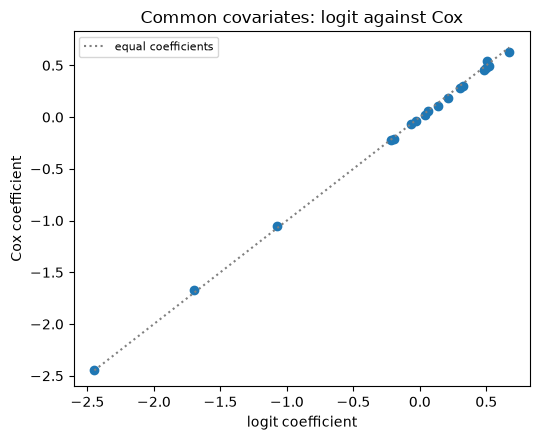

In [3]:
# Align the coefficients that the discrete-time logit and the Cox model share and compare them
dth = {c["name"]: c for c in ladder["L1-dth"]["coefficients"]}
cox = {c["name"]: c for c in ladder["L2-cox"]["coefficients"]}
common = [name for name in cox if name in dth]
logit_values = np.array([dth[n]["estimate"] for n in common])
cox_values = np.array([cox[n]["estimate"] for n in common])
std_errors = np.array([dth[n]["std_error"] for n in common])
print("common covariates:", len(common), "| only in the discrete-time rung:", len(dth) - len(common))
print("largest absolute difference:", round(float(np.abs(logit_values - cox_values).max()), 4))
print("correlation:", round(float(np.corrcoef(logit_values, cox_values)[0, 1]), 5))
print("largest difference in standard errors of the logit:",
      round(float(np.max(np.abs(logit_values - cox_values) / std_errors)), 2))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(logit_values, cox_values, color="tab:blue")
span = [logit_values.min(), logit_values.max()]
ax.plot(span, span, color="grey", linestyle=":", label="equal coefficients")
ax.set_xlabel("logit coefficient")
ax.set_ylabel("Cox coefficient")
ax.set_title("Common covariates: logit against Cox")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The 18 shared coefficients lie almost on the diagonal: their correlation is 0.9998 and the largest absolute difference is 0.0389, which is 3.2 standard errors of the logit. The agreement is expected. For a small period hazard $h$ the logit $\log\bigl(h/(1-h)\bigr)$ is close to $\log h$, which is the scale of the Cox model, so the two methods estimate nearly the same covariate effects. The points that move away from the diagonal belong to the covariates with the largest period hazard, where the approximation is worst. The choice between the two is therefore not about the loan covariates but about what each can carry: only the logit can take the macroeconomy.

### Step 2: the macro coefficients and their signs

Only the logit rung has macro covariates, standardised with a mean and a standard deviation. A validator checks each sign against economic expectation before reading anything else: a higher unemployment rate and a higher prime rate should raise the hazard of default, and higher real GDP growth should lower it. The expectation is a stated input of the lesson. The cell prints each estimate with its standard error, its z statistic and its hazard ratio per standard deviation, and whether the sign is the expected one.

In [4]:
# Read the macro coefficients of the logit rung and check their signs against the stated expectation
EXPECTED_SIGN = {"unemployment_rate": +1, "real_gdp_growth": -1, "prime_rate": +1}  # lesson input
for name, sign in EXPECTED_SIGN.items():
    c = dth[name]
    z = c["estimate"] / c["std_error"]
    matches = "yes" if np.sign(c["estimate"]) == sign else "no"
    print(f"{MACRO[name]:26s} | estimate {c['estimate']:+.4f} | standard error {c['std_error']:.4f}")
    print(f"{'':26s} | z {z:+.2f} | hazard ratio {np.exp(c['estimate']):.3f} | expected sign: {matches}")

unemployment rate          | estimate -0.0534 | standard error 0.0089
                           | z -5.99 | hazard ratio 0.948 | expected sign: no
real GDP growth            | estimate -0.1920 | standard error 0.0039
                           | z -49.11 | hazard ratio 0.825 | expected sign: yes
prime rate                 | estimate +0.1138 | standard error 0.0060
                           | z +18.86 | hazard ratio 1.120 | expected sign: yes


Real GDP growth lowers the hazard as expected, with an estimate of -0.1920, a z of -49.11 and a hazard ratio of 0.825 per standard deviation, and the prime rate raises it, +0.1138 with a ratio of 1.120. The unemployment rate has the wrong sign: its estimate is -0.0534, with a z of -5.99, so a higher unemployment lowers the hazard and the coefficient is statistically distinct from zero. This is the sensitivity that the committed finding `F-SCENARIO-ORDER` blames for the severely adverse scenario giving a lower ECL than the baseline in notebook 03. A validator rejects a macro coefficient of the wrong sign even when it is significant, because a significant effect that moves against the economy can signal collinearity among the macro variables over a short history, which this notebook does not test.

### Step 3: the three rungs on the same data, scored by the engine

The back-test rows keep, for each rung and origination cohort, the signed gap between the observed and the predicted cumulative PD at each horizon, defined as the observed minus the predicted. The cell recovers each rung's predicted curve from the observed one and the gap, and hands the three predicted curves to the engine's `lifetime_pd_backtest`, which returns the largest gap, the largest relative gap and a light. It does so for the pooled `all` cohort and for the 2007 vintage, the loans originated just before the crisis.

In [5]:
# Score each rung on two cohorts with the engine's lifetime test
rows = case["outputs"]["lifetime_backtest"]["rows"]
lifetime_rows = [t for t in case["tests"] if t["test_id"] == "ifrs9.lifetime_pd_backtest"]
tests = {(t["model_id"], t["segment"]): t for t in lifetime_rows}
curves = {}
for cohort in ("all", "2007"):
    cohort_rows = [r for r in rows if r["origination_cohort"] == cohort]
    months = np.array([r["months"] for r in cohort_rows])
    obs = np.array([r["observed_cumulative_pd"] for r in cohort_rows])
    curves[cohort] = (months, obs, {})
    for rung in RUNGS:
        row = tests[(rung, cohort)]
        predicted = obs - np.array(row["extras"]["signed_gap"])
        curves[cohort][2][rung] = predicted
        at_risk = np.full(months.size, row["n"], dtype=float)
        events = np.full(months.size, row["n_events"], dtype=float)
        score = ifrs9.lifetime_pd_backtest(months, predicted, obs, at_risk, events, model_id=rung, segment=cohort)
        relative = max(score.extras["relative_gap"])
        print("cohort", "pooled" if cohort == "all" else cohort, "|", RUNG_NAME[rung])
        print(f"   largest gap {score.metric:.4f} | largest relative gap {relative:.4f}")
        print("   light without the correlation:", LIGHT[score.light.value])

cohort pooled | Kaplan-Meier
   largest gap 0.0427 | largest relative gap 0.9147
   light without the correlation: red
cohort pooled | discrete-time logit
   largest gap 0.0167 | largest relative gap 0.3228
   light without the correlation: amber
cohort pooled | Cox
   largest gap 0.0427 | largest relative gap 1.0791
   light without the correlation: red
cohort 2007 | Kaplan-Meier
   largest gap 0.1240 | largest relative gap 3.1225
   light without the correlation: red
cohort 2007 | discrete-time logit
   largest gap 0.0859 | largest relative gap 1.2625
   light without the correlation: red
cohort 2007 | Cox
   largest gap 0.1163 | largest relative gap 3.2459
   light without the correlation: red


The engine's lifetime test, called without the asset correlation, reads the relative gap and not the Vasicek band of notebook 05, so these lights are stricter than the committed ones. On the pooled cohort the discrete-time logit has the smallest largest gap, 0.0167 with a relative gap of 0.3228 and a light of amber, while the Kaplan-Meier and Cox rungs have 0.0427 and relative gaps of 0.9147 and 1.0791, red. On the 2007 vintage the three gaps are 0.1240, 0.0859 and 0.1163 and all three are red, with relative gaps above 1. The ranking of the rungs does not change between the cohorts, with the logit first, but even the best rung is far from the outcome of the vintage that met the crisis.

### Step 3b: the 2007 vintage drawn

The 2007 vintage is the stress test of a lifetime PD: loans written at the top of the cycle that then went through the crisis. The figure draws the cumulative default observed for that vintage with the Kaplan-Meier estimate, and the curve each of the three rungs predicted, over the six horizons.

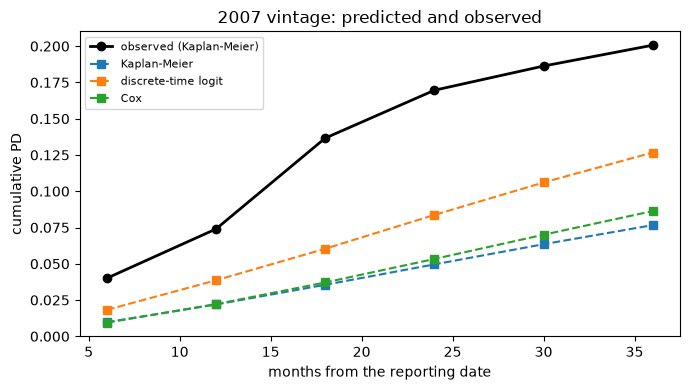

In [6]:
# Draw the 2007 vintage: the observed cumulative default and the curve each rung predicted
months7, obs7, predicted7 = curves["2007"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(months7, obs7, color="black", marker="o", linewidth=2, label="observed (Kaplan-Meier)")
for rung, color in zip(RUNGS, ("tab:blue", "tab:orange", "tab:green")):
    ax.plot(months7, predicted7[rung], color=color, marker="s", linestyle="--", label=RUNG_NAME[rung])
ax.set_xlabel("months from the reporting date")
ax.set_ylabel("cumulative PD")
ax.set_title("2007 vintage: predicted and observed")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The observed curve of the 2007 vintage rises to about 0.20 at 36 months, and the three predictions stay below it at every horizon: the Kaplan-Meier rung reaches 0.0766 at 36 months, the Cox rung 0.0863 and the logit 0.1267. The logit is the closest because its macro covariates raise the hazard in the crisis quarters, and still it covers little more than half of the realised default. The Kaplan-Meier and Cox curves are blind to the macroeconomy and to the vintage, so they describe an average loan of the book and miss the loans written at the top of the cycle. The macro covariates narrow the gap and do not close it.

### Step 4: what the rung choice costs in ECL

A lifetime PD matters through the ECL. The cell prices a stated account, an exposure of 100,000 USD at 8% a year with the loss given default of the segment of loans over 20 years, over a 36-month horizon with five curves: the observed one and the predicted curve of each rung for the pooled cohort. Each curve goes through `from_cumulative` to get its marginal PD, and `ecl_scenario` turns it into money. The exposure and the rate are inputs of the lesson, and the figure is left to the numbers.

In [7]:
# Price the stated account over 36 months with each rung's predicted curve and with the observed one
months_all, obs_all, predicted_all = curves["all"]
LGD = {s["segment_id"]: s["lgd"] for s in fit["lgd"]["segments"]}["term-gt-240"]
EAD, EIR = 100_000.0, np.array([0.08])  # stated inputs of the lesson
priced = {}
for label, curve in (("observed", obs_all), *[(RUNG_NAME[r], predicted_all[r]) for r in RUNGS]):
    structure = tsm.from_cumulative(curve, months_all)
    marginal = structure.marginal[None, :]
    priced[label] = float(ecl_engine.ecl_scenario(marginal, LGD, EAD, EIR, months_all, 36)[0])
reference = priced["observed"]
for label, value in priced.items():
    print(f"{label:24s} | 36-month ECL, USD {value:9.2f} | over the observed {value / reference:6.3f}")

observed                 | 36-month ECL, USD   5175.62 | over the observed  1.000
Kaplan-Meier             | 36-month ECL, USD   3114.33 | over the observed  0.602
discrete-time logit      | 36-month ECL, USD   4548.98 | over the observed  0.879
Cox                      | 36-month ECL, USD   3095.79 | over the observed  0.598


The rung choice is a choice about money. Priced on the observed cumulative default of the pooled cohort, which is what happened and not a forecast, the stated account would have cost 5,175.62 USD of ECL over 36 months. The logit's curve gives 4,548.98 USD, 0.879 of that, and the Kaplan-Meier and Cox curves give 3,114.33 and 3,095.79 USD, about 0.60 of it. A bank that provisioned with either of the macro-blind rungs would have held 40% less than the outcome, and even the logit falls 12% short. The pooled cohort includes the crisis, which is why every rung under-predicts, and the ranking is the same as in the back-test.

### Step 5: prepayment as censoring against a competing exit

C06 treats prepayment as censoring (finding `F-PREPAYMENT`): the cause-specific default hazard is the whole of the lifetime PD. The research recommends a competing-risks view, in which a loan that repays can no longer default (Fine and Gray, 1999; Botha and Verster, 2025). The cell takes the Kaplan-Meier curve, recovers its hazard with `from_cumulative`, adds a stated prepayment hazard of 0, 0.5%, 1% and 2% a quarter with `competing_risks`, and prices the lifetime ECL of the stated account of step 4 under each default incidence. The figure draws the incidence curves.

prepayment hazard per quarter 0.0
   default incidence at 36 months: 0.04394
   lifetime ECL, USD: 5915.44
   censoring over competing: 1.0
prepayment hazard per quarter 0.005
   default incidence at 36 months: 0.04222
   lifetime ECL, USD: 5453.55
   censoring over competing: 1.0847
prepayment hazard per quarter 0.01
   default incidence at 36 months: 0.04056
   lifetime ECL, USD: 5034.42
   censoring over competing: 1.175
prepayment hazard per quarter 0.02
   default incidence at 36 months: 0.03744
   lifetime ECL, USD: 4306.99
   censoring over competing: 1.3734


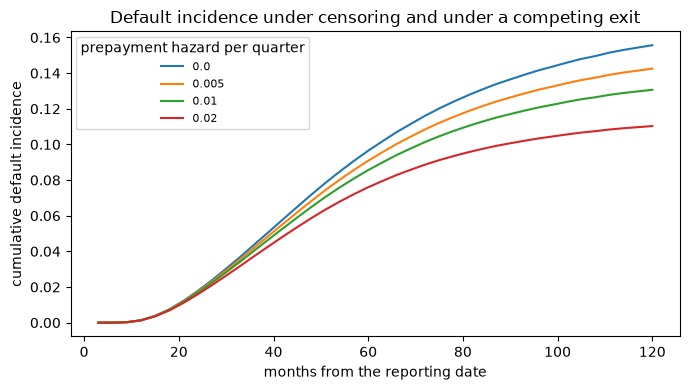

In [8]:
# Add a stated prepayment hazard to the Kaplan-Meier curve and compare incidence and ECL
km = ladder["L0-km"]["baseline"]
km_months = np.array(km["months"])
single = tsm.from_cumulative(np.array(km["cumulative_pd"]), km_months)
at_36 = int(np.flatnonzero(km_months == 36)[0])
incidence, ecl_life = {}, {}
for prepay in (0.0, 0.005, 0.01, 0.02):
    competing = tsm.competing_risks(single.hazard, np.full(single.hazard.shape, prepay), km_months)
    incidence[prepay] = competing.cumulative_default
    marginal = competing.marginal_default[None, :]
    ecl_life[prepay] = float(ecl_engine.ecl_scenario(marginal, LGD, EAD, EIR, km_months, int(km_months[-1]))[0])
    print("prepayment hazard per quarter", prepay)
    print("   default incidence at 36 months:", round(float(incidence[prepay][at_36]), 5))
    print("   lifetime ECL, USD:", round(ecl_life[prepay], 2))
    print("   censoring over competing:", round(ecl_life[0.0] / ecl_life[prepay], 4))

fig, ax = plt.subplots(figsize=(7, 4))
for prepay, curve in incidence.items():
    ax.plot(km_months, curve, label=f"{prepay}")
ax.set_xlabel("months from the reporting date")
ax.set_ylabel("cumulative default incidence")
ax.set_title("Default incidence under censoring and under a competing exit")
ax.legend(title="prepayment hazard per quarter", fontsize=8)
fig.tight_layout()
plt.show()

Adding a prepayment exit lowers the default incidence, and the censoring view overstates it. With a stated prepayment hazard of 0.5%, 1% and 2% a quarter the cumulative default at 36 months falls from 0.04394 to 0.04222, 0.04056 and 0.03744, and the lifetime ECL of the stated account falls from 5,915.44 USD to 5,453.55, 5,034.42 and 4,306.99. The ratio of the censoring ECL to the competing one is 1.0847, 1.175 and 1.3734. The curves separate more the longer the horizon, so the choice matters most for the long loans of the book. The prepayment hazards are inputs of the lesson and not estimates, so the result is a sensitivity: the cautious side of the censoring view has a price that grows with prepayment.

### Step 6: the satellite and the history of the factor

The one-factor conversion gives the systematic factor $z$ of each past quarter from the book's realised default rate (`fit.pit.z_hat`), and a satellite regresses that factor on the macro variables so that a scenario can be turned into a path of $z$. The cell prints the satellite's coefficients with the sign the factor should have, and converts the 63-quarter history of the factor back into the default rate it implies with `ttc_to_pit`, using the book's through-the-cycle PD and correlation. The figure draws the factor and the default rate it implies.

satellite intercept and autoregressive term: 13.3395 0.0
unemployment rate          | coefficient -1.0554 | expected sign for the factor: yes
real GDP growth            | coefficient +0.3289 | expected sign for the factor: yes
prime rate                 | coefficient -1.4056 | expected sign for the factor: yes
quarters of factor history: 63
mean and standard deviation of the factor:
-0.15 0.731
last value of the factor: -1.8
implied default rate, smallest and largest:
0.003 0.0671


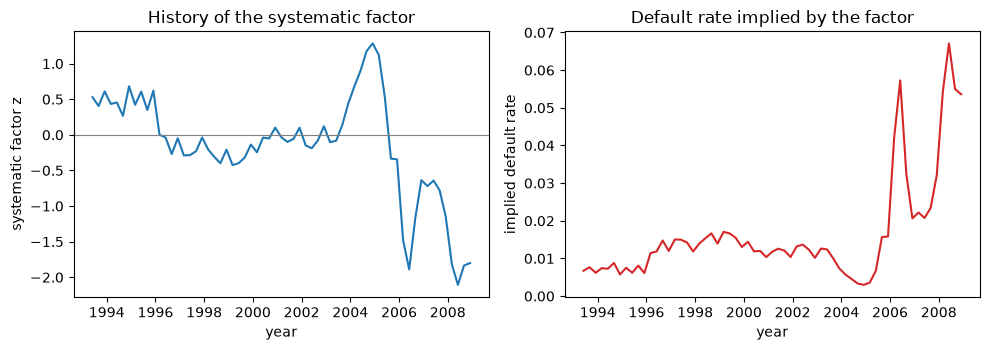

In [9]:
# Read the satellite and the factor history, and convert the history to the default rates it implies
pit = fit["pit"]
satellite = pit["satellite"]
params = case["outputs"]["non_linearity"]["parameters"]
EXPECTED_FACTOR_SIGN = {"unemployment_rate": -1, "real_gdp_growth": +1, "prime_rate": -1}  # stated expectation
print("satellite intercept and autoregressive term:", round(satellite["intercept"], 4), satellite["ar1"])
for c in satellite["coefficients"]:
    sign_ok = "yes" if np.sign(c["value"]) == EXPECTED_FACTOR_SIGN[c["name"]] else "no"
    print(f"{MACRO[c['name']]:26s} | coefficient {c['value']:+.4f} | expected sign for the factor: {sign_ok}")
history = np.array([p["z"] for p in pit["z_hat"]])
years = [int(p["period"][:4]) + (int(p["period"][5:7]) - 1) / 12 for p in pit["z_hat"]]
implied = tsm.ttc_to_pit(np.full(history.size, params["pd_ttc"]), pit["rho"], history)
print("quarters of factor history:", history.size)
print("mean and standard deviation of the factor:")
print(round(float(history.mean()), 3), round(float(history.std()), 3))
print("last value of the factor:", round(float(history[-1]), 3))
print("implied default rate, smallest and largest:")
print(round(float(implied.min()), 4), round(float(implied.max()), 4))

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.plot(years, history, color="tab:blue")
left.axhline(0.0, color="grey", linewidth=0.8)
left.set_xlabel("year")
left.set_ylabel("systematic factor z")
left.set_title("History of the systematic factor")
right.plot(years, implied, color="tab:red")
right.set_xlabel("year")
right.set_ylabel("implied default rate")
right.set_title("Default rate implied by the factor")
fig.tight_layout()
plt.show()

The satellite has the expected signs: the factor falls with the unemployment rate (-1.0554) and the prime rate (-1.4056) and rises with growth (+0.3289). The history over 63 quarters has a mean of -0.15 and a standard deviation of 0.731 and ends at -1.80, the crisis. Converted back, the factor implies a default rate between 0.30% and 6.71%, a range of more than twenty times, which is the cycle the term structure has to carry. Note a disagreement between the two layers: in the hazard model the unemployment rate lowers the PD, while in the satellite it lowers the factor, which raises the PD. The file does not say why, and a validator reads it as a model finding.

### Step 7: the scenario paths of the factor, turned into default rates

The artifact keeps three scenario paths of the factor, one per macroeconomic scenario, over 120 months. The cell converts each path into a path of conditional default rates with `ttc_to_pit`, weights the three scenarios at each date with `weighted_pit_pd` and the committed scenario weights, and compares the weighted rate with the rate at the weighted mean factor, the quantity notebook 03 showed to be too low. The figure draws the factor paths on the left and the default-rate paths with the two weighted measures on the right.

same start in the three scenarios: [-1.432 -1.432 -1.432]
factor at the end of the path: [0.879 0.879 0.879]
month 42 | z: [-1.205 -1.035 -0.956]
weighted default rate: 0.03162
default rate at the mean factor: 0.03153


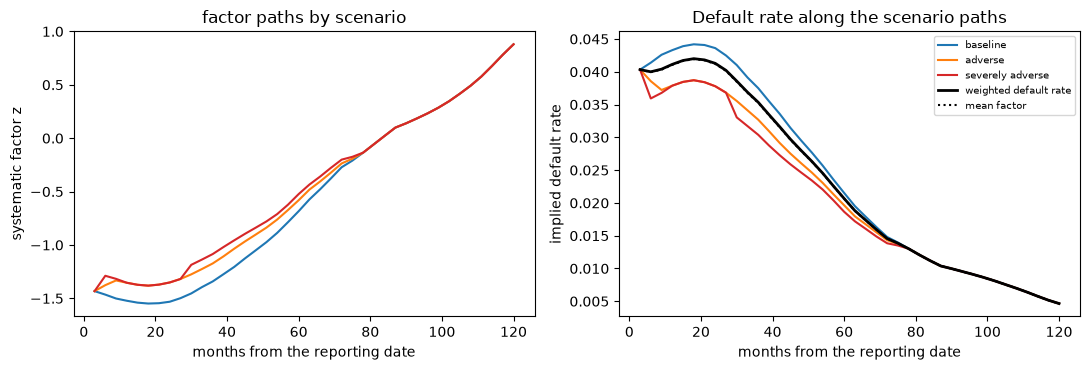

In [10]:
# Convert the factor paths into default-rate paths and weight them with the engine
definitions = fit["scenario_definitions"]
months_path = [p["months"] for p in definitions[0]["z_path"]]
z_paths = np.array([[p["z"] for p in d["z_path"]] for d in definitions])
weights = np.array([d["weight"] for d in definitions])
rate_paths = np.array([tsm.ttc_to_pit(np.full(z.size, params["pd_ttc"]), pit["rho"], z) for z in z_paths])
pd_ttc, rho = params["pd_ttc"], pit["rho"]
weighted = np.array([tsm.weighted_pit_pd(pd_ttc, rho, z_paths[:, t], weights) for t in range(len(months_path))])
at_mean = tsm.ttc_to_pit(np.full(len(months_path), params["pd_ttc"]), pit["rho"], weights @ z_paths)
print("same start in the three scenarios:", np.round(z_paths[:, 0], 3))
print("factor at the end of the path:", np.round(z_paths[:, -1], 3))
k = months_path.index(42)
print("month", 42, "| z:", np.round(z_paths[:, k], 3))
print("weighted default rate:", round(float(weighted[k]), 5))
print("default rate at the mean factor:", round(float(at_mean[k]), 5))

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
names = ("baseline", "adverse", "severely adverse")
for z, rate, name, color in zip(z_paths, rate_paths, names, ("tab:blue", "tab:orange", "tab:red")):
    left.plot(months_path, z, color=color, label=name)
    right.plot(months_path, rate, color=color, label=name)
right.plot(months_path, weighted, color="black", linewidth=2, label="weighted default rate")
right.plot(months_path, at_mean, color="black", linestyle=":", label="mean factor")
left.set_xlabel("months from the reporting date")
left.set_ylabel("systematic factor z")
left.set_title("factor paths by scenario")
right.set_xlabel("months from the reporting date")
right.set_ylabel("implied default rate")
right.set_title("Default rate along the scenario paths")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

The three scenario paths start at -1.432 and end at +0.879, which is the reversion to the long run that the ECB letter of 2020 asks for: the weight on the short-term forecast decays. In between the baseline is the lowest path, -1.205 at month 42, against -1.035 for the adverse and -0.956 for the severely adverse scenario, the reverse of the expected severity order, and a lower factor is a worse year. On the right, the weighted default rate at month 42 is 0.03162 against 0.03153 at the mean factor, 0.3% higher, the small PD-level non-linearity of notebook 03. The inverted order is the macro layer's fault and shows up in the factor before it reaches any ECL.

## Results

**Answer:** The three rungs of the product are the simplest survival methods the research lists (Kaplan-Meier, a discrete-time logit with macro covariates and a Cox model), and all three under-predict the crisis vintage: for the 2007 cohort the largest gap between the predicted and the observed cumulative PD is 0.1240, 0.0859 and 0.1163, and on the pooled book the logit prices the 36-month ECL of the stated account at 4548.98 USD against 5175.62 on the observed curve (0.879) while the other two reach about 0.60; treating prepayment as censoring instead of a competing exit gives a lifetime ECL that is 1.0847, 1.175 and 1.3734 times the competing one for prepayment hazards of 0.5%, 1% and 2% a quarter.

- **The logit and the Cox model agree closely, not identically.** On the 18 shared covariates the correlation of the coefficients is 0.9998 and the largest absolute difference is 0.0389, which is 3.2 standard errors of the logit; the two scales differ more where the period hazard is larger, as the approximation $\mathrm{logit}\,h \approx \log h$ says.
- **One macro sign is wrong.** Real GDP growth lowers the hazard as expected (-0.1920, a hazard ratio of 0.825) and the prime rate raises it (+0.1138, 1.120). The unemployment rate lowers it (-0.0534, 0.948), the opposite of the expected sign and statistically distinct from zero. This is the sensitivity that the committed finding `F-SCENARIO-ORDER` blames for the inverted scenario order.
- **The engine's lifetime test ranks the rungs the same way on both cohorts.** The logit has the smallest gap (0.0167 pooled, 0.0859 on 2007) and the Kaplan-Meier and Cox rungs 0.0427 and 0.1240, and 0.0427 and 0.1163. The relative-gap lights are red for every rung on the 2007 vintage.
- **The rung choice has a price in ECL.** The observed curve prices the stated account at 5175.62 USD over 36 months, the logit at 4548.98 and the Kaplan-Meier and Cox curves at 3114.33 and 3095.79.
- **Censoring against a competing exit.** The Kaplan-Meier curve gives a cumulative default of 0.04394 at 36 months; with prepayment hazards of 0.5%, 1% and 2% a quarter the incidence is 0.04222, 0.04056 and 0.03744 and the lifetime ECL 5453.55, 5034.42 and 4306.99 USD against 5915.44 under censoring.
- **The satellite has the expected signs, the paths revert, and the order is inverted.** The factor falls with unemployment (-1.0554) and the prime rate (-1.4056) and rises with growth (+0.3289). The three scenario paths start at -1.432 and end at +0.879. At month 42 the baseline is below the adverse and the severely adverse (-1.205, -1.035 and -0.956), the reverse of the expected severity order.

What this notebook does not show: it reads the fits and does not refit them, because the raw loan file is not committed. The mixture cure, survival forest, deep survival, age-period-cohort and multistate methods of the state of the art are not run by the product, and whether any package for them is available is UNVERIFIED. The prepayment hazards, the exposure and the rate are inputs of the lesson, not estimates, and the observed outcomes are charge-offs of SBA loans.

## Summary

- The three C06 rungs are the survival methods the research recommends at its simplest: the Kaplan-Meier curve, a discrete-time logit with macro covariates and a Cox model without time-varying covariates; the mixture cure, forest, deep and multistate methods are not run.
- The logit and the Cox coefficients agree closely on the common covariates, because the period hazard is small.
- The macro layer is where the rungs differ and where the model fails a validator's sign check: unemployment has the wrong sign in the hazard, which inverts the order of the scenarios.
- The logit rung wins the engine's lifetime test and the pricing of the stated account, but every rung under-predicts the cumulative PD at every horizon, and the crisis vintage most.
- Treating prepayment as censoring overstates the lifetime default incidence and the ECL, by more at longer horizons; the macro paths revert to the long run as the ECB letter asks.

**What to try next.** Change `EXPECTED_SIGN` and see which coefficients fail; add a prepayment hazard of 3% to the competing-risks cell; read the same tables in the `models-rd-2020-06.json` file and compare the signs. Then continue with notebook 08, which demonstrates the claim of this topic.

## References

- Botha, A. and Verster, T. (2025), Approaches for modelling the term-structure of default risk under IFRS 9: a tutorial using discrete-time survival analysis, equations 6 to 10. https://arxiv.org/abs/2507.15441
- Botha, A., Verster, T. and Breedt, R. (2025), Modelling the term-structure of default risk under IFRS 9 within a multistate regression framework. https://arxiv.org/abs/2502.14479
- Shumway, T. (2001), Forecasting bankruptcy more accurately: a simple hazard model, Journal of Business 74(1), 101-124. https://doi.org/10.1086/209665
- Cox, D. R. (1972), Regression models and life-tables, Journal of the Royal Statistical Society B 34(2), 187-202. https://doi.org/10.1111/j.2517-6161.1972.tb00899.x
- Fine, J. P. and Gray, R. J. (1999), A proportional hazards model for the subdistribution of a competing risk, Journal of the American Statistical Association 94(446), 496-509. https://doi.org/10.1080/01621459.1999.10474144
- Breeden, J. L. (2016), Incorporating lifecycle and environment in loan-level forecasts and stress tests, European Journal of Operational Research 255(2), 649-658. https://doi.org/10.1016/j.ejor.2016.06.008
- ECB Banking Supervision (2020), IFRS 9 in the context of the coronavirus (COVID-19) pandemic, letter to banks of 1 April 2020: weights on short-term forecasts and reversion to long-term values. https://www.bankingsupervision.europa.eu/press/letterstobanks/shared/pdf/2020/ssm.2020_letter_IFRS_9_in_the_context_of_the_coronavirus_COVID-19_pandemic~4cab8e5650.en.pdf
- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- EBA (2023), IFRS 9 implementation by EU institutions, 2023 monitoring report, EBA/Rep/2023/36, paragraphs 29 to 33 and 94 to 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm